# Week 6 · Class 1 — Your First Machine Learning Model 🏠📈 (live coding)

**90 min · hands-on** · tools: `pandas`, `matplotlib`, `seaborn`, `scikit-learn`

This notebook is the practical side of today's slides. We train our **first ML model**: a **linear regression** that predicts house prices.

| Part | Time | What we do |
|---|---|---|
| 0 | 3' | Setup |
| 1 | 10' | Warm-up: salary vs experience (a model that works perfectly) |
| 2 | 10' | Meet the California housing data |
| 3 | 12' | Quick exploration with ML in mind |
| 4 | 8' | Features, target and the train/test split |
| 5 | 5' | A baseline: the "dumb" model to beat |
| 6 | 12' | Simple regression: income → house value |
| 7 | 12' | Multiple regression: all features |
| 8 | 10' | Diagnose the errors |
| 9 | 3' | Recap |

🧑‍💻 = we write it **together**. 📚 **At home:** Part B at the end (5 exercises with solutions).

> 🧪 **Saturday labs:** *Regression Analysis* and *Intro to Scikit-Learn* use exactly the steps of this notebook.

---
## 0 · Setup ⚙️

📁 **The data**
- **Colab:** nothing to do. Colab ships the file in `sample_data/california_housing_train.csv`.
- **VS Code / Jupyter:** put `california_housing_train.csv` (or the smaller `california_housing_test.csv` from the Week 6 folder) next to this notebook.

The cell below tries each place in turn and tells you which file it found.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

---
## 1 · Warm-up: salary vs years of experience 💼

Before real data, a tiny clean example: **30 employees**, their years of experience and their salary.
The question: *can we predict salary from experience?*

In [ ]:
years = [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7, 3.9, 4.0, 4.0, 4.1, 4.5,
         4.9, 5.1, 5.3, 5.9, 6.0, 6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5]
salary = [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 64445, 57189,
          63218, 55794, 56957, 57081, 61111, 67938, 66029, 83088, 81363, 93940,
          91738, 98273, 101302, 113812, 109431, 105582, 116969, 112635, 122391, 121872]
salaries = pd.DataFrame({"years": years, "salary": salary})
salaries.head()

🧑‍💻 **Code with me:** plot salary against years. Does a straight line look reasonable?

In [ ]:
# scatter plot: years on x, salary on y

Now our first model, in three lines. scikit-learn always wants:
- **X**: a *table* of features (2D, so double brackets `[["years"]]`)
- **y**: one *column*, the target

In [ ]:
# create LinearRegression, fit on years -> salary, print intercept_ and coef_

📖 **Read it:** every extra year of experience goes with about **+9,450 €** of salary, on average. The intercept is the predicted salary at 0 years.

🧑‍💻 **Code with me:** predict the salary for 5 and 12 years, and draw the line.

In [ ]:
# predict for 5 and 12 years, plot data + red line, print R²

✅ R² ≈ 0.96: the line explains almost all the variation. Great, but **real data is rarely this clean**, and 12 years is already outside our data (extrapolation!).
Now the real thing.

---
## 2 · Meet the California housing data 🏠

- 1990 US census, **one row = one district** (a block of a few hundred homes), not one house.
- **Target:** `median_house_value`, in dollars.
- **Features:** location, age of the houses, counts of rooms / people / households, and median income (in **tens of thousands** of $).

In [4]:
path = "../data/california_housing_full.csv"

df = pd.read_csv(path).drop(columns="ocean_proximity")
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41.00,880.00,129.00,322.00,126.00,8.33,"452,600.00"
1,-122.22,37.86,21.00,"7,099.00","1,106.00","2,401.00","1,138.00",8.30,"358,500.00"
2,-122.24,37.85,52.00,"1,467.00",190.00,496.00,177.00,7.26,"352,100.00"
3,-122.25,37.85,52.00,"1,274.00",235.00,558.00,219.00,5.64,"341,300.00"
4,-122.25,37.85,52.00,"1,627.00",280.00,565.00,259.00,3.85,"342,200.00"
...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.00,"1,665.00",374.00,845.00,330.00,1.56,"78,100.00"
20636,-121.21,39.49,18.00,697.00,150.00,356.00,114.00,2.56,"77,100.00"
20637,-121.22,39.43,17.00,"2,254.00",485.00,"1,007.00",433.00,1.70,"92,300.00"
20638,-121.32,39.43,18.00,"1,860.00",409.00,741.00,349.00,1.87,"84,700.00"


🧑‍💻 **Code with me:** column types, missing values and a summary.

In [7]:
# column types and missing values

df = df.dropna()
df.info()


<class 'pandas.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
dtypes: float64(9)
memory usage: 1.6 MB


In [9]:
# summary statistics (transposed)

df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,433.00",-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,"20,433.00",35.63,2.14,32.54,33.93,34.26,37.72,41.95
housing_median_age,"20,433.00",28.63,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,"20,433.00","2,636.50","2,185.27",2.00,"1,450.00","2,127.00","3,143.00","39,320.00"
total_bedrooms,"20,433.00",537.87,421.39,1.00,296.00,435.00,647.00,"6,445.00"
population,"20,433.00","1,424.95","1,133.21",3.00,787.00,"1,166.00","1,722.00","35,682.00"
households,"20,433.00",499.43,382.30,1.00,280.00,409.00,604.00,"6,082.00"
median_income,"20,433.00",3.87,1.90,0.50,2.56,3.54,4.74,15.00
median_house_value,"20,433.00","206,864.41","115,435.67","14,999.00","119,500.00","179,700.00","264,700.00","500,001.00"


🤔 **Look at the max of `median_house_value`.** It is exactly 500,001. In the census, every value above 500k was written as 500,001: the target is **capped**.

In [10]:
# share of districts with value >= 500,000

capped = (df["median_house_value"] >= 500_000).mean()
print("proportion of districts capped at 500k:", capped)

proportion of districts capped at 500k: 0.04820633289286938


---
## 3 · Quick exploration with ML in mind 🔍

Before modelling we ask three questions:
1. What does the **target** look like?
2. Which features move **together with** the target?
3. Any surprises (outliers, caps, strange scales)?

🧑‍💻 **Code with me:** histogram of the target.

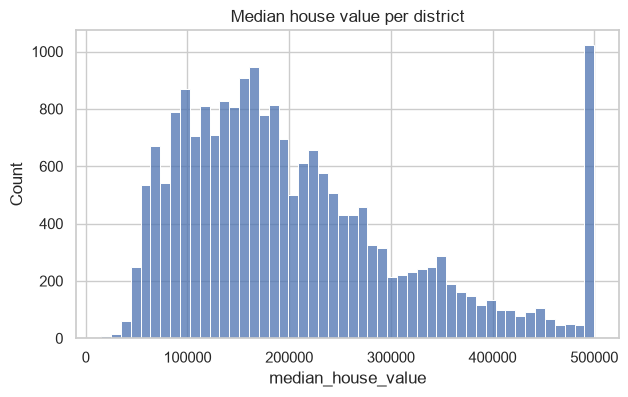

In [11]:
# histogram of median_house_value, 50 bins

plt.figure(figsize=(7, 4))
sns.histplot(df["median_house_value"], bins=50)
plt.title("Median house value per district")
plt.show()

The spike on the right is the cap. Skewed target, long right tail: keep this in mind for Thursday (log transforms).

🧑‍💻 **Code with me:** correlation of every feature with the target, sorted.

In [13]:
# correlation of each column with the target, sorted

corr = df.corr()["median_house_value"].drop("median_house_value").sort_values(ascending=False)
corr

median_income         0.69
total_rooms           0.13
housing_median_age    0.11
households            0.06
total_bedrooms        0.05
population           -0.03
longitude            -0.05
latitude             -0.14
Name: median_house_value, dtype: float64

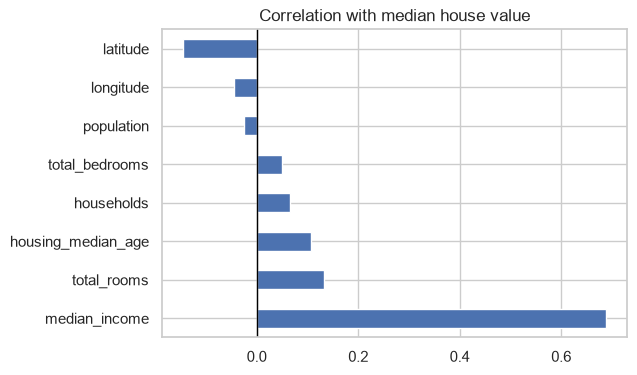

In [14]:
# horizontal bar chart of corr
plt.figure(figsize=(6, 4))
corr.plot(kind="barh")
plt.axvline(0, color="black", lw=1)
plt.title("Correlation with median house value")
plt.show()

📖 **Income** is by far the strongest single signal. Counts like `total_rooms` barely correlate: a district with many rooms may simply be a **big** district, not a rich one.

🧑‍💻 **Code with me:** where are the expensive districts?

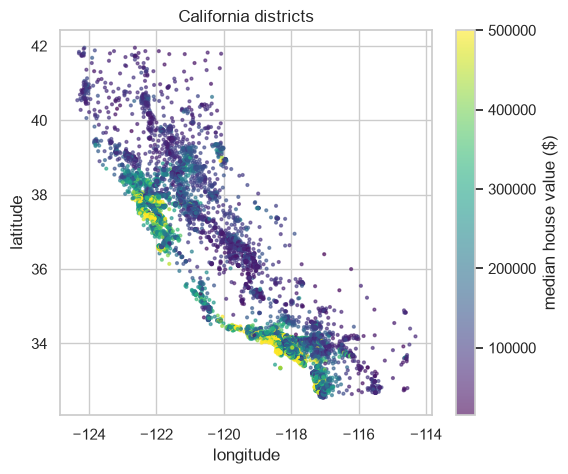

In [15]:
# map: longitude vs latitude, coloured by house value

plt.figure(figsize=(6, 5))
plt.scatter(df["longitude"], df["latitude"], c=df["median_house_value"],
            cmap="viridis", s=4, alpha=0.6)
plt.colorbar(label="median house value ($)")
plt.xlabel("longitude"); plt.ylabel("latitude")
plt.title("California districts")
plt.show()

The coast (San Francisco Bay, Los Angeles) is expensive. Location matters, but **not in a straight line**: keep that in mind when we read the results.

---
## 4 · Features, target and the train/test split ✂️

- **X** = everything except the target. **y** = the target.
- We hide **20%** of the districts in a **test set**. The model never sees them during training: they are our "new exam".
- `random_state=42` makes the random shuffle the same every time (so we all get the same numbers).

In [18]:
# X = all columns but the target, y = target; 80/20 split with random_state=42
## explanatory variables vs target variable
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

> ⚠️ From now on: **fit on train, evaluate on test.** Never let the test set influence a choice.

---
## 5 · A baseline: the "dumb" model to beat 🪨

The simplest possible prediction: **always predict the average price of the training set.**
Any real model must do better than this, or it is useless.

We'll measure everything with a small helper function (remember functions from Week 1?):

In [31]:
# def evaluate(y_true, y_pred, name): print and return MAE, RMSE, R²

def evaluate(y_true, y_pred, name = "model"):
    # print MAE, RSME and R2 in the set of predictions
    mae = mean_absolute_error(y_true, y_pred)
    rsme = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    #print(f"{name: <22} MAE = {mae:>9, .0f} $, RSME ={rsme:>9, .0f}, R2 = {r2:6.3f}")
    return {"model": name, "MAE": mae, "RSME":  rsme, "R2 score": r2}

In [21]:
## train test split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [23]:
len(X_train)/len(X)

0.799980423824206

In [28]:
y_train.mean()

np.float64(206644.40009788328)

In [29]:
y_test

14416   245,800.00
16383   137,900.00
7731    218,200.00
1410    220,800.00
1335    170,500.00
           ...    
8291    500,001.00
6274    157,900.00
2997    100,200.00
13440   127,700.00
14797   133,700.00
Name: median_house_value, Length: 4087, dtype: float64

In [26]:
# predict y_train.mean() for every test row and evaluate
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_pred

array([206644.40009788, 206644.40009788, 206644.40009788, ...,
       206644.40009788, 206644.40009788, 206644.40009788], shape=(4087,))

In [33]:
results = [evaluate(y_test, baseline_pred)]
results

[{'model': 'model',
  'MAE': 92836.5012171493,
  'RSME': np.float64(116946.10165720902),
  'R2 score': -8.847464530803428e-05}]

📖 R² = 0 (or just below): by definition, the mean explains nothing. MAE ≈ how wrong we are **on average** when we know nothing.

---
## 6 · Simple regression: income → house value 📈

One feature, exactly like the salary warm-up.

🧑‍💻 **Code with me:** fit a model on `median_income` only.

In [35]:
X_train["median_income"]

17727   4.70
2057    3.41
6453    3.66
4619    2.24
15266   3.55
        ... 
11397   5.43
12081   4.80
5447    3.10
866     5.29
15948   3.89
Name: median_income, Length: 16346, dtype: float64

In [37]:
X_train[["median_income"]]

,median_income
17727,4.70
2057,3.41
6453,3.66
4619,2.24
15266,3.55
...,...
11397,5.43
12081,4.80
5447,3.10
866,5.29


In [38]:
# LinearRegression on X_train[['median_income']], print intercept_ and coef_

model_income = LinearRegression()
model_income.fit(X_train[["median_income"]], y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[41751.96]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['median_income']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.504e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [41]:
print("intercept b0:", model_income.intercept_)
print("slope b1:",  model_income.coef_)
## y = b0 +b1x

intercept b0: 45035.228175380034
slope b1: [41751.95797205]


📖 **Read it:** a district whose median income is 10k$ higher has, on average, houses worth roughly **40k$ more**.

In [43]:
# predict on X_test[['median_income']] and evaluate
pred_income = model_income.predict(X_test[["median_income"]])
results.append(evaluate(y_test, pred_income, "income_only"))

In [44]:
results

[{'model': 'model',
  'MAE': 92836.5012171493,
  'RSME': np.float64(116946.10165720902),
  'R2 score': -8.847464530803428e-05},
 {'model': 'income_only',
  'MAE': 63374.551304332555,
  'RSME': np.float64(84976.53325615863),
  'R2 score': 0.4719622857489497}]

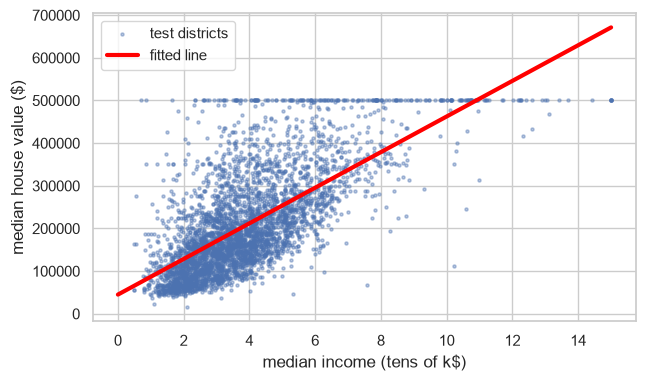

In [45]:
# scatter test income vs value + the red fitted line
plt.figure(figsize=(7, 4))
plt.scatter(X_test["median_income"], y_test, s=5, alpha=0.4, label="test districts")
grid = pd.DataFrame({"median_income": np.linspace(0, 15, 50)})
plt.plot(grid["median_income"], model_income.predict(grid), color="red", lw=3, label="fitted line")
plt.xlabel("median income (tens of k$)"); plt.ylabel("median house value ($)")
plt.legend(); plt.show()

🤔 **Predict:** what will happen to R² if we give the model **all eight** features?

---
## 7 · Multiple regression: all features 🧮

Same three lines, just a bigger X. The model now learns **one coefficient per feature**.

🧑‍💻 **Code with me:**

In [46]:
# LinearRegression on all of X_train, predict X_test, evaluate

model_all = LinearRegression()
model_all.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-42546.71,-42336.04, 1155.1 ,..., -36.76, 41.64, 40293.28]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.57e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [47]:
pred_all = model_all.predict(X_test)
results.append(evaluate(y_test, pred_all, "all 8 features"))

Let's put all results side by side:

In [48]:
results

[{'model': 'model',
  'MAE': 92836.5012171493,
  'RSME': np.float64(116946.10165720902),
  'R2 score': -8.847464530803428e-05},
 {'model': 'income_only',
  'MAE': 63374.551304332555,
  'RSME': np.float64(84976.53325615863),
  'R2 score': 0.4719622857489497},
 {'model': 'all 8 features',
  'MAE': 51372.6721705002,
  'RSME': np.float64(70156.12045736372),
  'R2 score': 0.6400865688993749}]

In [49]:
# results as a DataFrame
pd.DataFrame(results).set_index("model")

,MAE,RSME,R2 score
model,,,
model,"92,836.50","116,946.10",-0.00
income_only,"63,374.55","84,976.53",0.47
all 8 features,"51,372.67","70,156.12",0.64


🧑‍💻 **Code with me:** is the model **overfitting**? Compare the score on the training data with the score on the test data.

In [ ]:
# evaluate model_all on train and on test

📖 Train and test scores are close → **no overfitting**. A straight-line model is simple; its problem is more likely **underfitting** (too simple to capture everything).

Now the coefficients:

In [50]:
# coefficients as a Series indexed by column names, sorted
coefs = pd.Series(model_all.coef_, index = X.columns).sort_values()
coefs

#y = b0 + b1X1 + b2 X2 + b3 X3 + ...= bX

longitude            -42,546.71
latitude             -42,336.04
population               -36.76
total_rooms               -8.44
households                41.64
total_bedrooms           115.83
housing_median_age     1,155.10
median_income         40,293.28
dtype: float64

⚠️ **Careful when reading these:**
- **Units differ.** `median_income` is in tens of k$, `total_rooms` is a count in the thousands. A big coefficient is not automatically an important feature.
- **Correlated features.** `total_rooms`, `total_bedrooms`, `households` and `population` move together, so their coefficients can take surprising signs.
- Thursday we **scale** the features and use **regularisation**, which makes coefficients much easier to compare.

---
## 8 · Diagnose the errors 🩺

One number hides a lot. Two plots every regression deserves:
1. **Predicted vs actual:** a perfect model puts every dot on the diagonal.
2. **Residuals vs predicted:** residual = actual − predicted. We want a shapeless cloud around 0.

🧑‍💻 **Code with me:**

In [ ]:
# two plots side by side: predicted vs actual, residuals vs predicted

📖 **What we see:**
- A **vertical wall at 500k**: the capped districts. The model predicts above and below, but the truth is stuck at 500k.
- A **diagonal stripe** in the residual plot: that is the cap again.
- Some **negative predictions**: a straight line happily goes below 0, but prices cannot.

In [ ]:
# count negative predictions and the largest absolute residual

🧭 **So the model is not bad, it is a baseline.** A straight line explains about 60% of the variation in prices. To do better we need:
- **better features** (rooms *per household*, income on a log scale…) → **Thursday**
- **non-linear models** (trees, boosting) → **Week 8**

---
## 9 · Recap 🧭

| Step | Code |
|---|---|
| features & target | `X = df.drop(columns="target")`, `y = df["target"]` |
| split | `train_test_split(X, y, test_size=0.2, random_state=42)` |
| create → fit → predict | `model = LinearRegression()` · `model.fit(X_train, y_train)` · `model.predict(X_test)` |
| read the model | `model.intercept_`, `model.coef_` |
| metrics | `mean_absolute_error`, `mean_squared_error` (→ √ for RMSE), `r2_score` |
| always | compare with a **baseline**, compare **train vs test**, **plot the residuals** |

---
# 📚 Part B · At home — 5 exercises

Each exercise has a hint and a solution cell. Try first, then compare.

### Exercise 1 · Predict a new district 🏡
A district at longitude −122.2, latitude 37.8, houses 30 years old, 2,000 rooms, 400 bedrooms, 1,000 people, 380 households, median income 6.0.
What does `model_all` predict?

*Hint:* build a one-row DataFrame with **the same columns, in the same order** as `X`.

In [ ]:
# your code here

### Exercise 2 · Which single feature is the best predictor? 🥇
For **each** feature, fit a one-feature linear regression on train and compute R² on test. Show the results sorted.

*Hint:* a `for` loop over `X.columns`, and a dictionary to collect the scores.

In [ ]:
# your code here

Income wins by far. Note how weak latitude and longitude are **on their own**: location matters, but not along a straight line.

### Exercise 3 · How stable is the score? 🎲
Repeat the split + fit + R² for `random_state` = 0, 1, …, 9. What are the min, max and mean test R²?

*Hint:* put the three steps inside a loop and store each R² in a list.

In [ ]:
# your code here

The score moves a little with the split. That is why on Thursday we use **cross-validation**: average over several splits instead of trusting one.

### Exercise 4 · What if we drop the capped districts? ✂️
Remove the rows with `median_house_value >= 500_000`, then split, fit and evaluate again. Does R² go up or down? Why might this be **dangerous** in a real product?

*Hint:* filter `df` with a boolean mask first.

In [ ]:
# your code here

R² goes **down** (fewer extreme prices to explain, so the mean baseline is also better), and the model now **knows nothing about expensive districts**. If you deploy it, it will be badly wrong on exactly those cases. Changing the data to make a score look good is a classic trap.

### Exercise 5 · Your first engineered feature 🛠️
Create `rooms_per_household = total_rooms / households` and `income_squared = median_income ** 2`. Add them to X, refit, and compare test R² with `model_all`.

*Hint:* `df.assign(...)` or `df["new"] = ...`, then repeat the split with the same `random_state`.

In [ ]:
# your code here

Only a small gain: a straight line still cannot bend around the non-linear patterns. Thursday we do **feature engineering** properly (scaling, logs, polynomials, pipelines) and see much bigger effects. 🚀